COMPREHENSIVE MODEL COMPARISON WITH ALL METRICS

Configuration:
  - Training windows: 200
  - Testing windows: 50
  - Window size: 7 jobs
  - Output directory: model_comparison_20260306_041056

Loading data...
Dataset shape: (400000, 6)
Columns: ['Job_ID', 'Arrival_Time', 'Service_Time', 'Deadline_Exp', 'Deadline_Uni', 'Deadline_Erl']

Step 1: Generating 200 training windows...


Generating training data: 100%|██████████| 200/200 [00:07<00:00, 28.49it/s]



Training data shape: (200, 12)
Target distribution:
target_tq
1.5      2
2.0      2
5.0    196
Name: count, dtype: int64

Step 2: Training 60 ML Models...


Training models:  20%|██        | 12/60 [00:22<00:17,  2.76it/s]

Error calculating metrics: Mean Tweedie deviance error with power=1 can only be used on non-negative y and strictly positive y_pred.


...

Training models: 100%|██████████| 60/60 [00:33<00:00,  1.79it/s]



Successfully trained 56 models

Top 5 Models by R² Score:
      Model  R2         RMSE          MAE         MAPE
   AdaBoost 1.0 0.000000e+00 0.000000e+00 0.000000e+00
Extra Trees 1.0 0.000000e+00 0.000000e+00 0.000000e+00
GP (Matern) 1.0 7.199691e-10 3.109850e-10 8.777833e-11
   GP (RBF) 1.0 1.064790e-09 6.411590e-10 1.541397e-10
  Radius NN 1.0 0.000000e+00 0.000000e+00 0.000000e+00

Step 3: Testing 56 models on 50 windows...


Testing windows: 100%|██████████| 50/50 [00:06<00:00,  7.34it/s]



Step 4: Creating comprehensive visualizations...


IndexError: positional indexers are out-of-bounds

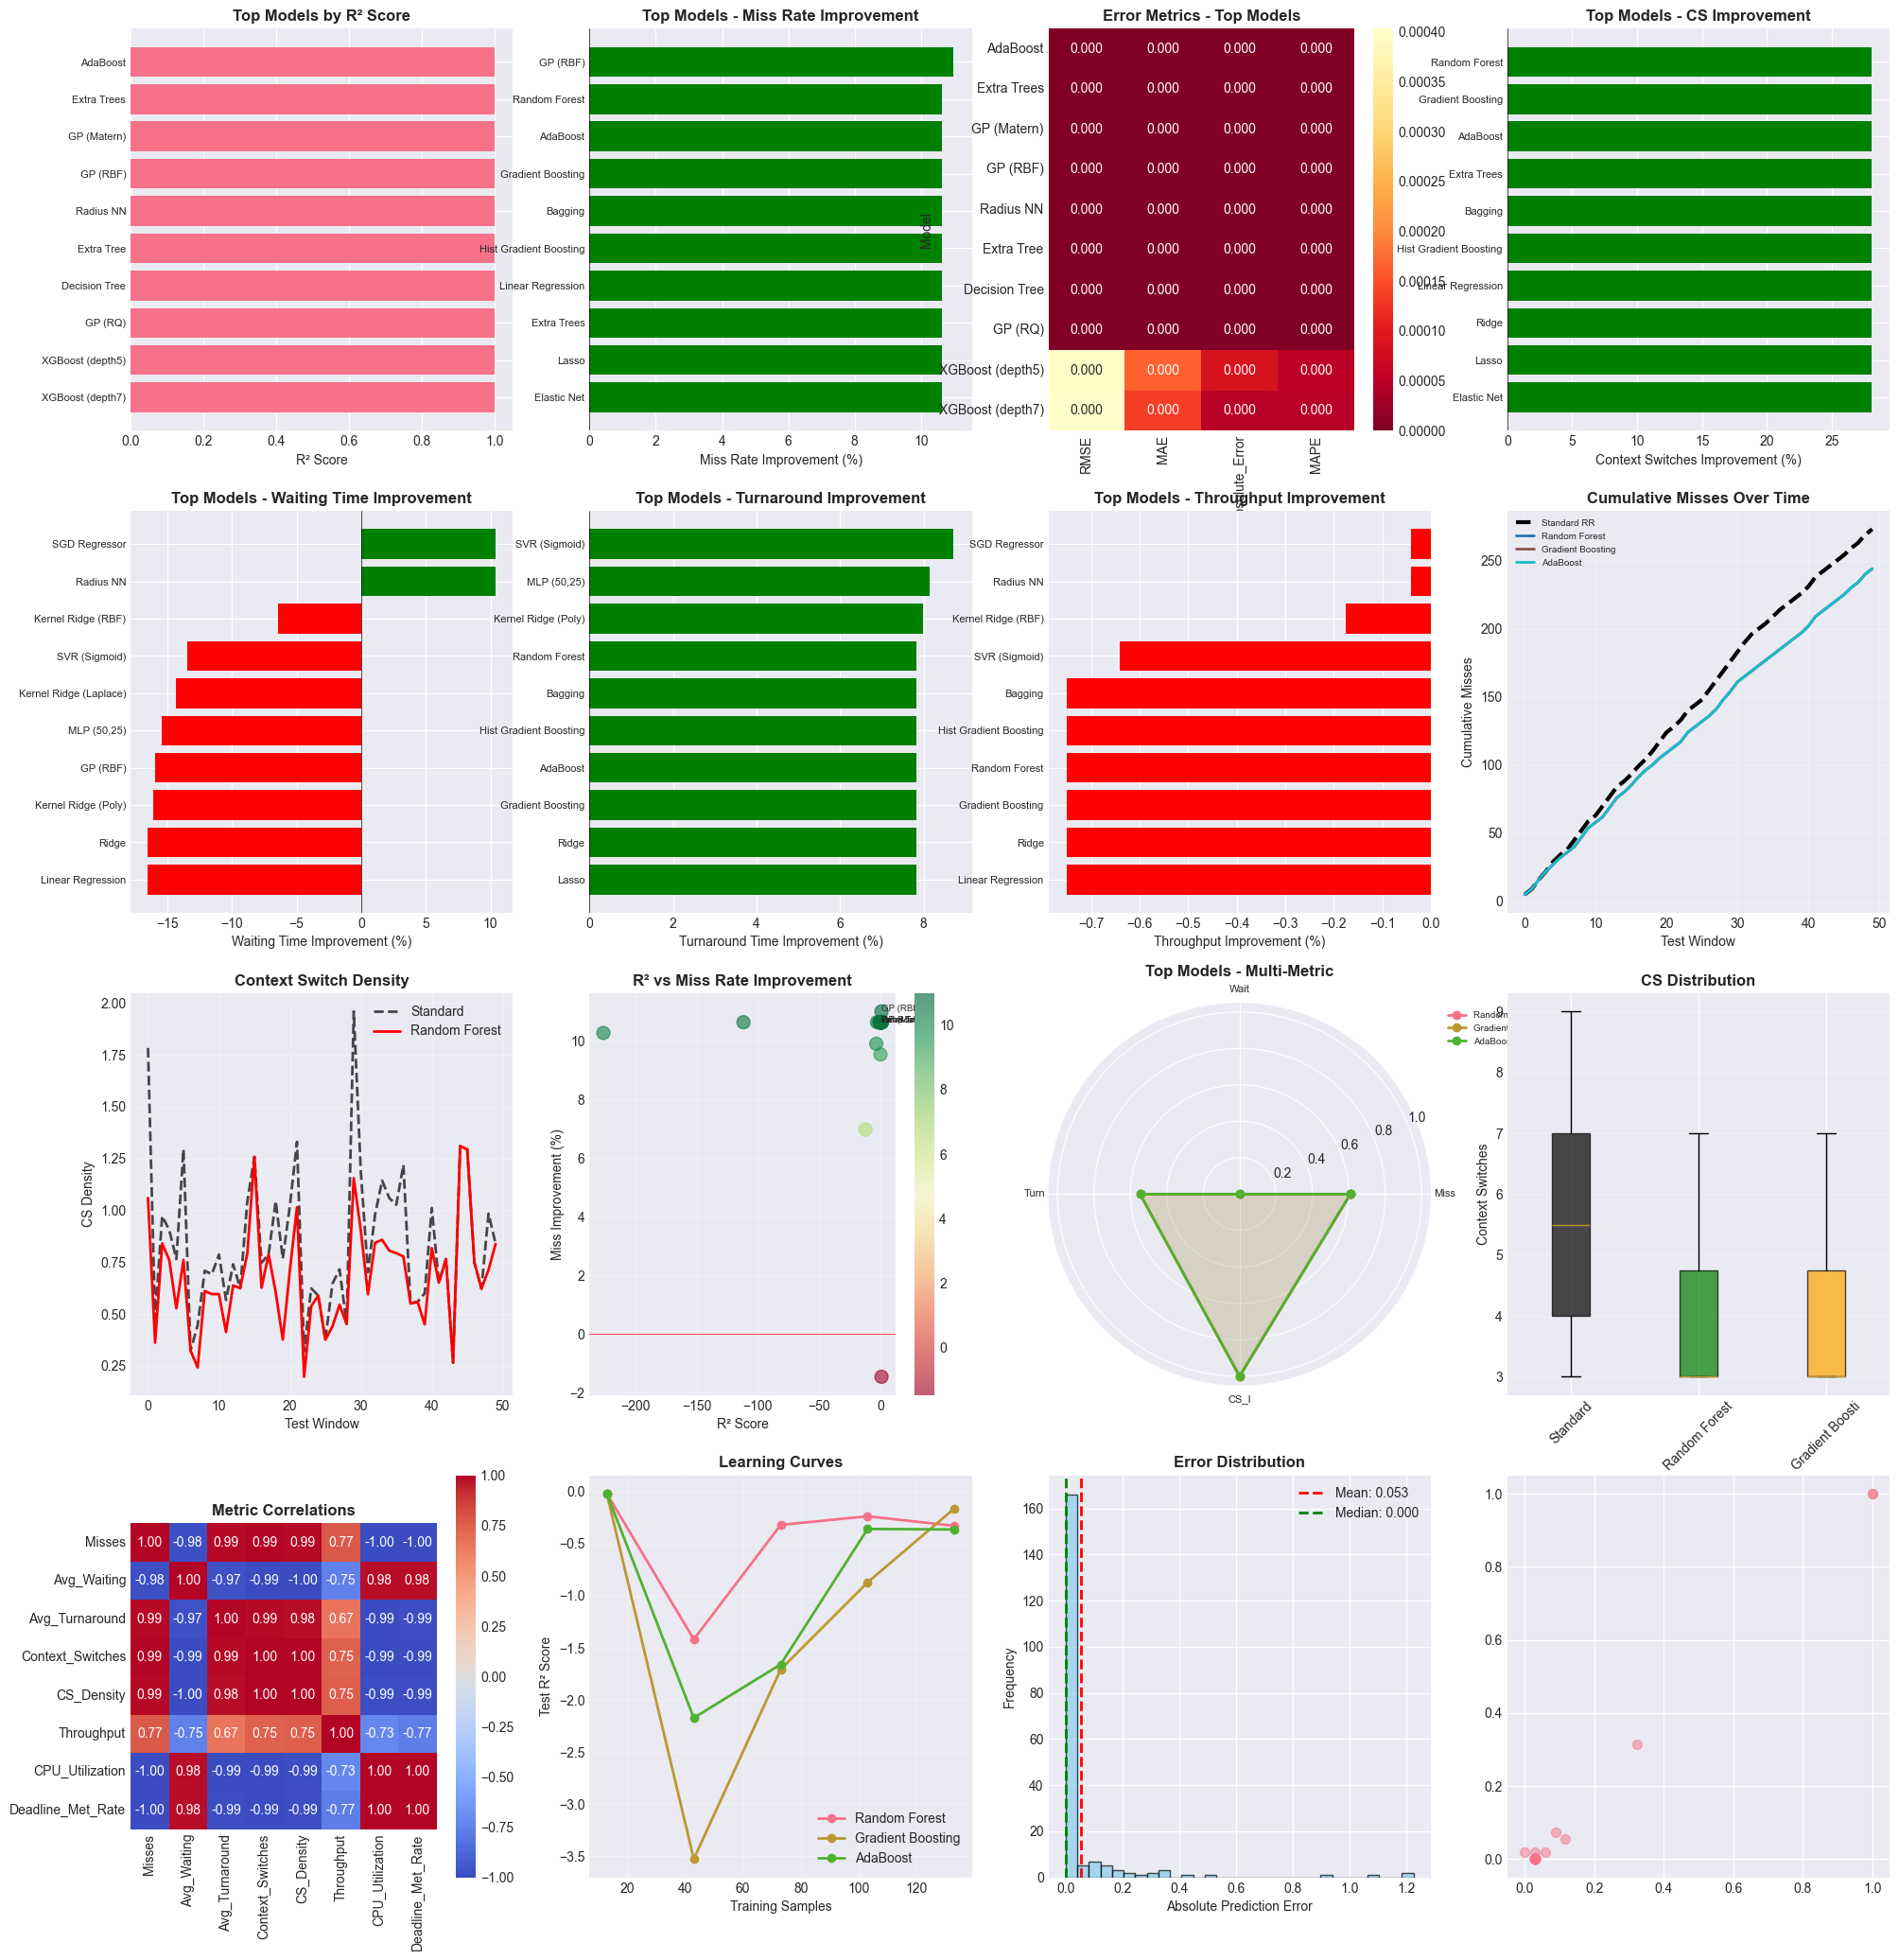

In [2]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import warnings
warnings.filterwarnings('ignore')
import time
import os
from datetime import datetime
import scipy.stats as stats
from scipy.spatial.distance import cosine
from sklearn.metrics import confusion_matrix, classification_report

# Machine Learning models
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor,
    ExtraTreesRegressor, BaggingRegressor, HistGradientBoostingRegressor
)
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge,
    SGDRegressor, PassiveAggressiveRegressor, HuberRegressor,
    RANSACRegressor, TheilSenRegressor, PoissonRegressor, GammaRegressor,
    TweedieRegressor
)
from sklearn.svm import SVR, LinearSVR, NuSVR
from sklearn.neighbors import KNeighborsRegressor, RadiusNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.cross_decomposition import PLSRegression, CCA
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

# Additional models
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, WhiteKernel

# Metrics - Comprehensive error metrics
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    explained_variance_score, max_error, mean_absolute_percentage_error,
    median_absolute_error, mean_squared_log_error,
    mean_poisson_deviance, mean_gamma_deviance,
    d2_absolute_error_score, d2_pinball_score, d2_tweedie_score
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.model_selection import cross_val_score, KFold, cross_validate, learning_curve

# ----------------------------
# CONFIGURABLE PARAMETERS
# ----------------------------
N_TRAIN_WINDOWS = 200      # Reduced for speed
N_TEST_WINDOWS = 50        # Keep reasonable for comparison
WINDOW_SIZE = 7            
WINDOW_STEP = 3            
RANDOM_SEED = 42           

# Other configuration
CANDIDATE_SLICES = [0.1, 0.2, 0.5, 1.0, 1.5, 2.0, 5.0]
CS_OVERHEAD = 0.05

# Create output directory
OUTPUT_DIR = f"model_comparison_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ----------------------------
# 1. Enhanced Simulator with Multiple Metrics
# ----------------------------
class SimulationCache:
    """Cache for simulation results"""
    def __init__(self):
        self.cache = {}
        self.hits = 0
        self.misses = 0
    
    def get_key(self, batch_df, tq):
        key = (batch_df['Job_ID'].iloc[0], batch_df['Arrival_Time'].iloc[0], tq)
        return key
    
    def get(self, batch_df, tq):
        key = self.get_key(batch_df, tq)
        if key in self.cache:
            self.hits += 1
            return self.cache[key]
        self.misses += 1
        return None
    
    def put(self, batch_df, tq, result):
        key = self.get_key(batch_df, tq)
        self.cache[key] = result

sim_cache = SimulationCache()

def run_detailed_simulation(df_batch, tq, use_cache=True):
    """
    Enhanced simulation that returns multiple metrics:
    - misses: number of deadline misses
    - avg_waiting_time: average waiting time
    - avg_turnaround_time: average turnaround time
    - context_switches: number of context switches
    - additional metrics: max_waiting, response_time, etc.
    """
    if use_cache:
        cached_result = sim_cache.get(df_batch, tq)
        if cached_result is not None:
            return cached_result
    
    time_val = df_batch['Arrival_Time'].min()
    
    # Prepare jobs with additional tracking fields
    jobs = df_batch.copy().rename(columns={'Service_Time': 'bt', 'Deadline_Exp': 'deadline'})
    jobs = jobs.sort_values('Arrival_Time').reset_index(drop=True)
    
    # Add tracking fields
    jobs['original_bt'] = jobs['bt'].copy()
    jobs['completion_time'] = np.nan
    jobs['first_start_time'] = np.nan
    jobs['waiting_time'] = 0
    jobs['turnaround_time'] = 0
    jobs['response_time'] = 0  # Time from arrival to first execution
    jobs['times_preempted'] = 0
    jobs['cs_incurred'] = 0  # Context switches incurred by this job
    
    jobs_list = jobs.to_dict('records')
    
    ready_queue = []
    completed = 0
    misses = 0
    last_pid = None
    context_switches = 0
    total_waiting_time = 0
    completed_jobs = 0
    turnaround_times = []
    waiting_times = []
    response_times = []
    preemptions = []
    cs_per_job = []
    execution_intervals = []  # Track execution intervals for CS pattern analysis
    
    while completed < len(jobs_list) or ready_queue:
        # Move arrived jobs to ready queue
        while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
            new_job = jobs_list.pop(0)
            ready_queue.append(new_job)
        
        if not ready_queue:
            if jobs_list:
                time_val = jobs_list[0]['Arrival_Time']
                continue
            break

        # Sort by Earliest Deadline First (EDF)
        ready_queue.sort(key=lambda x: x['deadline'])
        p = ready_queue.pop(0)

        # Track first start time for waiting/response time calculation
        if pd.isna(p['first_start_time']):
            p['first_start_time'] = time_val
            p['waiting_time'] = time_val - p['Arrival_Time']
            p['response_time'] = time_val - p['Arrival_Time']
            total_waiting_time += p['waiting_time']
            waiting_times.append(p['waiting_time'])
            response_times.append(p['response_time'])

        # Context Switch
        if last_pid is not None and last_pid != p['Job_ID']:
            time_val += CS_OVERHEAD
            context_switches += 1
            p['cs_incurred'] += 1
            execution_intervals.append({
                'time': time_val,
                'from_pid': last_pid,
                'to_pid': p['Job_ID'],
                'type': 'context_switch'
            })
        
        # Execution
        exec_time = min(p['bt'], tq)
        if p['bt'] < tq * 1.1: 
            exec_time = p['bt']
            
        p['bt'] -= exec_time
        time_val += exec_time
        last_pid = p['Job_ID']
        
        execution_intervals.append({
            'time': time_val,
            'pid': p['Job_ID'],
            'duration': exec_time,
            'type': 'execution'
        })

        if p['bt'] <= 0:
            # Job completed
            p['completion_time'] = time_val
            if time_val > p['deadline']:
                misses += 1
            
            # Calculate turnaround time
            turnaround = time_val - p['Arrival_Time']
            turnaround_times.append(turnaround)
            
            completed += 1
            completed_jobs += 1
            preemptions.append(p['times_preempted'])
            cs_per_job.append(p['cs_incurred'])
        else:
            p['times_preempted'] += 1
            # Re-check for arrivals during execution
            while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
                ready_queue.append(jobs_list.pop(0))
            ready_queue.append(p)
    
    # Calculate all metrics
    result = {
        # Miss metrics
        'misses': misses,
        'miss_rate': misses / len(df_batch) * 100 if len(df_batch) > 0 else 0,
        
        # Waiting time metrics
        'avg_waiting_time': np.mean(waiting_times) if waiting_times else 0,
        'median_waiting_time': np.median(waiting_times) if waiting_times else 0,
        'min_waiting_time': np.min(waiting_times) if waiting_times else 0,
        'max_waiting_time': np.max(waiting_times) if waiting_times else 0,
        'std_waiting_time': np.std(waiting_times) if waiting_times else 0,
        'q25_waiting_time': np.percentile(waiting_times, 25) if waiting_times else 0,
        'q75_waiting_time': np.percentile(waiting_times, 75) if waiting_times else 0,
        'iqr_waiting_time': np.percentile(waiting_times, 75) - np.percentile(waiting_times, 25) if waiting_times else 0,
        'skew_waiting_time': stats.skew(waiting_times) if len(waiting_times) > 1 else 0,
        'kurtosis_waiting_time': stats.kurtosis(waiting_times) if len(waiting_times) > 1 else 0,
        
        # Turnaround time metrics
        'avg_turnaround_time': np.mean(turnaround_times) if turnaround_times else 0,
        'median_turnaround_time': np.median(turnaround_times) if turnaround_times else 0,
        'min_turnaround_time': np.min(turnaround_times) if turnaround_times else 0,
        'max_turnaround_time': np.max(turnaround_times) if turnaround_times else 0,
        'std_turnaround_time': np.std(turnaround_times) if turnaround_times else 0,
        'q25_turnaround_time': np.percentile(turnaround_times, 25) if turnaround_times else 0,
        'q75_turnaround_time': np.percentile(turnaround_times, 75) if turnaround_times else 0,
        'iqr_turnaround_time': np.percentile(turnaround_times, 75) - np.percentile(turnaround_times, 25) if turnaround_times else 0,
        
        # Response time metrics
        'avg_response_time': np.mean(response_times) if response_times else 0,
        'median_response_time': np.median(response_times) if response_times else 0,
        'min_response_time': np.min(response_times) if response_times else 0,
        'max_response_time': np.max(response_times) if response_times else 0,
        'std_response_time': np.std(response_times) if response_times else 0,
        
        # Context switch metrics
        'context_switches': context_switches,
        'cs_per_job_avg': np.mean(cs_per_job) if cs_per_job else 0,
        'cs_per_job_max': np.max(cs_per_job) if cs_per_job else 0,
        'cs_per_job_std': np.std(cs_per_job) if cs_per_job else 0,
        'cs_density': context_switches / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0,
        
        # Preemption metrics
        'avg_preemptions': np.mean(preemptions) if preemptions else 0,
        'max_preemptions': np.max(preemptions) if preemptions else 0,
        'total_preemptions': sum(preemptions),
        'preemption_rate': sum(preemptions) / len(df_batch) if len(df_batch) > 0 else 0,
        
        # Throughput and efficiency
        'throughput': completed_jobs / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0,
        'cpu_utilization': sum(df_batch['Service_Time']) / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0,
        'scheduling_overhead': (context_switches * CS_OVERHEAD) / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0,
        
        # Deadline metrics
        'deadline_met_rate': (len(df_batch) - misses) / len(df_batch) * 100 if len(df_batch) > 0 else 0,
        
        # Raw data for further analysis
        'execution_intervals': execution_intervals
    }
    
    if use_cache:
        sim_cache.put(df_batch, tq, result)
    
    return result

def get_real_features(df_batch):
    """Extract features from a batch of jobs"""
    return {
        'avg_service': df_batch['Service_Time'].mean(),
        'arrival_rate': len(df_batch) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'min_deadline': df_batch['Deadline_Exp'].min(),
        'max_deadline': df_batch['Deadline_Exp'].max(),
        'service_std': df_batch['Service_Time'].std(),
        'service_skew': df_batch['Service_Time'].skew(),
        'deadline_range': df_batch['Deadline_Exp'].max() - df_batch['Deadline_Exp'].min(),
        'job_count': len(df_batch),
        'utilization': (df_batch['Service_Time'].sum()) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'deadline_variance': df_batch['Deadline_Exp'].var(),
        'service_quantile_25': df_batch['Service_Time'].quantile(0.25),
        'service_quantile_75': df_batch['Service_Time'].quantile(0.75)
    }

# ----------------------------
# 2. Complete Model Dictionary with Additional Models
# ----------------------------
def get_all_models():
    """Returns ALL ML models with additional variants"""
    models = {
        # Ensemble Methods
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'AdaBoost': AdaBoostRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Extra Trees': ExtraTreesRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Bagging': BaggingRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=RANDOM_SEED),
        
        # Linear Models
        'Linear Regression': LinearRegression(),
        'Ridge': Ridge(alpha=1.0),
        'Lasso': Lasso(alpha=0.01),
        'Elastic Net': ElasticNet(alpha=0.01, l1_ratio=0.5),
        'Bayesian Ridge': BayesianRidge(),
        'SGD Regressor': SGDRegressor(random_state=RANDOM_SEED, max_iter=1000),
        'Passive Aggressive': PassiveAggressiveRegressor(random_state=RANDOM_SEED),
        'Huber Regressor': HuberRegressor(),
        'RANSAC': RANSACRegressor(random_state=RANDOM_SEED),
        'TheilSen': TheilSenRegressor(random_state=RANDOM_SEED),
        'Poisson': PoissonRegressor(),
        'Gamma': GammaRegressor(),
        'Tweedie': TweedieRegressor(),
        
        # Support Vector Machines
        'SVR (RBF)': SVR(kernel='rbf'),
        'SVR (Linear)': LinearSVR(random_state=RANDOM_SEED, max_iter=1000),
        'SVR (Poly)': SVR(kernel='poly'),
        'SVR (Sigmoid)': SVR(kernel='sigmoid'),
        'NuSVR': NuSVR(),
        
        # Neighbors and Trees
        'KNN (3)': KNeighborsRegressor(n_neighbors=3),
        'KNN (5)': KNeighborsRegressor(n_neighbors=5),
        'KNN (7)': KNeighborsRegressor(n_neighbors=7),
        'KNN (10)': KNeighborsRegressor(n_neighbors=10),
        'Radius NN': RadiusNeighborsRegressor(radius=1.0),
        'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_SEED),
        'Extra Tree': ExtraTreeRegressor(random_state=RANDOM_SEED),
        
        # Neural Networks
        'MLP (50,)': MLPRegressor(hidden_layer_sizes=(50,), random_state=RANDOM_SEED, max_iter=500),
        'MLP (100,)': MLPRegressor(hidden_layer_sizes=(100,), random_state=RANDOM_SEED, max_iter=500),
        'MLP (50,25)': MLPRegressor(hidden_layer_sizes=(50,25), random_state=RANDOM_SEED, max_iter=500),
        'MLP (100,50)': MLPRegressor(hidden_layer_sizes=(100,50), random_state=RANDOM_SEED, max_iter=500),
        
        # Gaussian Processes with different kernels
        'GP (RBF)': GaussianProcessRegressor(kernel=RBF(), random_state=RANDOM_SEED),
        'GP (Matern)': GaussianProcessRegressor(kernel=Matern(), random_state=RANDOM_SEED),
        'GP (RQ)': GaussianProcessRegressor(kernel=RationalQuadratic(), random_state=RANDOM_SEED),
        
        # Kernel Methods
        'Kernel Ridge (RBF)': KernelRidge(kernel='rbf'),
        'Kernel Ridge (Poly)': KernelRidge(kernel='poly'),
        'Kernel Ridge (Laplace)': KernelRidge(kernel='laplacian'),
        
        # Advanced Tree Methods
        'XGBoost (50)': XGBRegressor(n_estimators=50, random_state=RANDOM_SEED),
        'XGBoost (100)': XGBRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'XGBoost (200)': XGBRegressor(n_estimators=200, random_state=RANDOM_SEED),
        'XGBoost (depth3)': XGBRegressor(max_depth=3, random_state=RANDOM_SEED),
        'XGBoost (depth5)': XGBRegressor(max_depth=5, random_state=RANDOM_SEED),
        'XGBoost (depth7)': XGBRegressor(max_depth=7, random_state=RANDOM_SEED),
        
        # Polynomial Features
        'Polynomial (deg 2)': make_pipeline(PolynomialFeatures(degree=2), LinearRegression()),
        'Polynomial (deg 3)': make_pipeline(PolynomialFeatures(degree=3), Ridge()),
        'Polynomial (deg 4)': make_pipeline(PolynomialFeatures(degree=4), Ridge(alpha=0.1)),
        
        # Cross Decomposition
        'PLS (2 comp)': PLSRegression(n_components=2),
        'PLS (3 comp)': PLSRegression(n_components=3),
        'PLS (5 comp)': PLSRegression(n_components=5),
        'CCA': CCA(n_components=2),
        
        # Isotonic Regression
        'Isotonic': IsotonicRegression(out_of_bounds='clip'),
        'Isotonic (increasing)': IsotonicRegression(increasing=True, out_of_bounds='clip'),
        'Isotonic (decreasing)': IsotonicRegression(increasing=False, out_of_bounds='clip'),
    }
    
    # Add Voting Ensemble variations
    from sklearn.ensemble import VotingRegressor
    
    # Simple voting
    estimators1 = [
        ('rf', RandomForestRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('gb', GradientBoostingRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('lr', Ridge())
    ]
    models['Voting (RF+GB+LR)'] = VotingRegressor(estimators=estimators1)
    
    # Tree-based voting
    estimators2 = [
        ('rf', RandomForestRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('et', ExtraTreesRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('xgb', XGBRegressor(n_estimators=50, random_state=RANDOM_SEED))
    ]
    models['Voting (RF+ET+XGB)'] = VotingRegressor(estimators=estimators2)
    
    # Linear voting
    estimators3 = [
        ('ridge', Ridge()),
        ('lasso', Lasso(alpha=0.01)),
        ('enet', ElasticNet(alpha=0.01))
    ]
    models['Voting (Ridge+Lasso+EN)'] = VotingRegressor(estimators=estimators3)
    
    return models

# ----------------------------
# 3. Comprehensive Error Metrics Function
# ----------------------------
def calculate_all_error_metrics(y_true, y_pred, model_name=""):
    """Calculate every possible error metric"""
    metrics = {}
    
    try:
        # Basic metrics
        metrics['MSE'] = mean_squared_error(y_true, y_pred)
        metrics['RMSE'] = np.sqrt(metrics['MSE'])
        metrics['MAE'] = mean_absolute_error(y_true, y_pred)
        metrics['R2'] = r2_score(y_true, y_pred)
        metrics['Explained_Variance'] = explained_variance_score(y_true, y_pred)
        metrics['Max_Error'] = max_error(y_true, y_pred)
        metrics['Median_Absolute_Error'] = median_absolute_error(y_true, y_pred)
        
        # Percentage errors
        mask = y_true != 0
        if mask.any():
            metrics['MAPE'] = mean_absolute_percentage_error(y_true[mask], y_pred[mask])
            metrics['SMAPE'] = 100 * np.mean(2 * np.abs(y_pred[mask] - y_true[mask]) / (np.abs(y_true[mask]) + np.abs(y_pred[mask])))
        else:
            metrics['MAPE'] = np.nan
            metrics['SMAPE'] = np.nan
        
        # Log errors
        if (y_true >= 0).all() and (y_pred >= 0).all():
            metrics['MSLE'] = mean_squared_log_error(y_true, y_pred)
            metrics['RMSLE'] = np.sqrt(metrics['MSLE'])
        else:
            metrics['MSLE'] = np.nan
            metrics['RMSLE'] = np.nan
        
        # Deviance metrics
        metrics['Poisson_Deviance'] = mean_poisson_deviance(y_true, y_pred)
        metrics['Gamma_Deviance'] = mean_gamma_deviance(y_true, y_pred)
        
        # D2 scores
        metrics['D2_Absolute_Error'] = d2_absolute_error_score(y_true, y_pred)
        metrics['D2_Pinball'] = d2_pinball_score(y_true, y_pred)
        metrics['D2_Tweedie'] = d2_tweedie_score(y_true, y_pred)
        
        # Error distribution metrics
        errors = y_true - y_pred
        abs_errors = np.abs(errors)
        pct_errors = np.abs(errors / (y_true + 1e-10)) * 100
        
        metrics['Mean_Error'] = np.mean(errors)
        metrics['Median_Error'] = np.median(errors)
        metrics['Std_Error'] = np.std(errors)
        metrics['Skew_Error'] = stats.skew(errors) if len(errors) > 1 else 0
        metrics['Kurtosis_Error'] = stats.kurtosis(errors) if len(errors) > 1 else 0
        
        metrics['Mean_Absolute_Error'] = np.mean(abs_errors)
        metrics['Median_Absolute_Error_Alt'] = np.median(abs_errors)
        metrics['Std_Absolute_Error'] = np.std(abs_errors)
        
        metrics['Mean_Percentage_Error'] = np.mean(pct_errors)
        metrics['Median_Percentage_Error'] = np.median(pct_errors)
        
        # Quantile errors
        for q in [5, 10, 25, 75, 90, 95]:
            if len(errors) > 0:
                metrics[f'Error_Q{q}'] = np.percentile(errors, q)
                metrics[f'AbsError_Q{q}'] = np.percentile(abs_errors, q)
            else:
                metrics[f'Error_Q{q}'] = np.nan
                metrics[f'AbsError_Q{q}'] = np.nan
        
        # Correlation metrics
        if len(y_true) > 1:
            metrics['Pearson_Corr'] = np.corrcoef(y_true, y_pred)[0, 1]
            metrics['Spearman_Corr'] = stats.spearmanr(y_true, y_pred)[0]
            metrics['Kendall_Corr'] = stats.kendalltau(y_true, y_pred)[0]
        else:
            metrics['Pearson_Corr'] = 0
            metrics['Spearman_Corr'] = 0
            metrics['Kendall_Corr'] = 0
        
        # Distance metrics
        if len(y_true) > 0:
            metrics['Cosine_Distance'] = cosine(y_true, y_pred)
            metrics['Euclidean_Distance'] = np.sqrt(np.sum((y_true - y_pred) ** 2))
            metrics['Manhattan_Distance'] = np.sum(np.abs(y_true - y_pred))
        else:
            metrics['Cosine_Distance'] = 0
            metrics['Euclidean_Distance'] = 0
            metrics['Manhattan_Distance'] = 0
        
        # Information criteria (simplified)
        n = len(y_true)
        k = 1  # approximate number of parameters
        metrics['AIC'] = n * np.log(metrics['MSE'] + 1e-10) + 2 * k
        metrics['BIC'] = n * np.log(metrics['MSE'] + 1e-10) + k * np.log(n)
        
        # Accuracy metrics (for classification version - if we discretize)
        y_true_class = np.digitize(y_true, bins=CANDIDATE_SLICES)
        y_pred_class = np.digitize(y_pred, bins=CANDIDATE_SLICES)
        
        metrics['Classification_Accuracy'] = accuracy_score(y_true_class, y_pred_class)
        metrics['Precision_Macro'] = precision_score(y_true_class, y_pred_class, average='macro', zero_division=0)
        metrics['Recall_Macro'] = recall_score(y_true_class, y_pred_class, average='macro', zero_division=0)
        metrics['F1_Macro'] = f1_score(y_true_class, y_pred_class, average='macro', zero_division=0)
        
        # Confusion matrix based metrics
        cm = confusion_matrix(y_true_class, y_pred_class, labels=range(len(CANDIDATE_SLICES)))
        if cm.size > 0 and cm.shape[0] == cm.shape[1]:
            metrics['Confusion_Matrix_Diagonal_Sum'] = np.trace(cm)
            metrics['Confusion_Matrix_Off_Diagonal_Sum'] = np.sum(cm) - np.trace(cm)
        
    except Exception as e:
        print(f"Error calculating metrics: {e}")
        # Set default values on error
        metrics = {f'Metric_Error': str(e)}
    
    return metrics

# ----------------------------
# 4. Main Execution
# ----------------------------
if __name__ == "__main__":
    # Set random seed
    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    
    start_time = time.time()
    
    print("="*80)
    print("COMPREHENSIVE MODEL COMPARISON WITH ALL METRICS")
    print("="*80)
    print(f"\nConfiguration:")
    print(f"  - Training windows: {N_TRAIN_WINDOWS}")
    print(f"  - Testing windows: {N_TEST_WINDOWS}")
    print(f"  - Window size: {WINDOW_SIZE} jobs")
    print(f"  - Output directory: {OUTPUT_DIR}")
    
    # Load data
    print("\nLoading data...")
    try:
        df = pd.read_csv("Kargahi_Movaghar_Source_Data.csv")
        print(f"Dataset shape: {df.shape}")
        print(f"Columns: {df.columns.tolist()}")
    except FileNotFoundError:
        print("Error: CSV file not found. Please check the file path.")
        exit(1)
    
    # Save raw data info
    with open(f"{OUTPUT_DIR}/dataset_info.txt", 'w') as f:
        f.write(f"Dataset: Kargahi_Movaghar_Source_Data.csv\n")
        f.write(f"Shape: {df.shape}\n")
        f.write(f"Columns: {df.columns.tolist()}\n")
        f.write(f"Service Time Stats:\n{df['Service_Time'].describe()}\n")
        f.write(f"Deadline Stats:\n{df['Deadline_Exp'].describe()}\n")
    
    # Generate training data
    print(f"\nStep 1: Generating {N_TRAIN_WINDOWS} training windows...")
    train_data = []
    train_window_details = []
    
    total_possible_indices = list(range(0, len(df) - WINDOW_SIZE, WINDOW_STEP))
    if len(total_possible_indices) > 0:
        train_indices = random.sample(total_possible_indices, min(N_TRAIN_WINDOWS, len(total_possible_indices)))
        train_indices.sort()
    else:
        print("Error: Not enough data for the specified window size")
        exit(1)
    
    for i in tqdm(train_indices, desc="Generating training data"):
        batch = df.iloc[i:i+WINDOW_SIZE]
        feats = get_real_features(batch)
        
        # Find best TQ based on misses only (for training target)
        best_tq, min_m = 1.0, float('inf')
        tq_results = {}
        
        for tq_val in CANDIDATE_SLICES:
            result = run_detailed_simulation(batch, tq_val)
            tq_results[tq_val] = result
            if result['misses'] <= min_m:
                min_m, best_tq = result['misses'], tq_val
        
        feats['target_tq'] = best_tq
        feats['window_start_idx'] = i
        train_data.append(feats)
        
        # Store detailed TQ results for this window
        window_detail = {'window_idx': i, 'best_tq': best_tq, 'best_misses': min_m}
        for tq_val in CANDIDATE_SLICES:
            res = tq_results[tq_val]
            window_detail[f'tq_{tq_val}_misses'] = res['misses']
            window_detail[f'tq_{tq_val}_miss_rate'] = res['miss_rate']
            window_detail[f'tq_{tq_val}_waiting'] = res['avg_waiting_time']
            window_detail[f'tq_{tq_val}_turnaround'] = res['avg_turnaround_time']
            window_detail[f'tq_{tq_val}_cs'] = res['context_switches']
            window_detail[f'tq_{tq_val}_cs_density'] = res['cs_density']
            window_detail[f'tq_{tq_val}_throughput'] = res['throughput']
        train_window_details.append(window_detail)
    
    # Prepare training data
    train_df = pd.DataFrame(train_data)
    X = train_df.drop(['target_tq', 'window_start_idx'], axis=1)
    y = train_df['target_tq']
    
    print(f"\nTraining data shape: {X.shape}")
    print(f"Target distribution:\n{y.value_counts().sort_index()}")
    
    # Save training data
    train_df.to_csv(f"{OUTPUT_DIR}/training_data.csv", index=False)
    pd.DataFrame(train_window_details).to_csv(f"{OUTPUT_DIR}/training_window_details.csv", index=False)
    
    # Get all models
    models_dict = get_all_models()
    print(f"\nStep 2: Training {len(models_dict)} ML Models...")
    
    # Train all models and collect comprehensive metrics
    trained_models = {}
    all_error_metrics = []
    prediction_details = []
    learning_curves_data = []
    
    # Cross-validation setup
    kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    
    for model_name, model in tqdm(models_dict.items(), desc="Training models"):
        try:
            # Train the model
            model.fit(X, y)
            trained_models[model_name] = model
            
            # Make predictions
            y_pred = model.predict(X)
            
            # Store predictions for each training sample
            for idx, (actual, pred) in enumerate(zip(y, y_pred)):
                prediction_details.append({
                    'model': model_name,
                    'training_sample_idx': idx,
                    'actual_tq': actual,
                    'predicted_tq': pred,
                    'rounded_tq': min(CANDIDATE_SLICES, key=lambda x: abs(x - pred)),
                    'absolute_error': abs(actual - pred),
                    'squared_error': (actual - pred) ** 2,
                    'percentage_error': abs(actual - pred) / (actual + 1e-10) * 100
                })
            
            # Calculate all error metrics
            error_metrics = calculate_all_error_metrics(y, y_pred, model_name)
            error_metrics['Model'] = model_name
            error_metrics['Status'] = 'Success'
            
            # Cross-validation scores
            try:
                cv_results = cross_validate(model, X, y, cv=kfold, 
                                           scoring=['r2', 'neg_mean_squared_error', 'neg_mean_absolute_error'],
                                           n_jobs=-1, return_estimator=False)
                
                error_metrics['CV_R2_Mean'] = cv_results['test_r2'].mean()
                error_metrics['CV_R2_Std'] = cv_results['test_r2'].std()
                error_metrics['CV_MSE_Mean'] = -cv_results['test_neg_mean_squared_error'].mean()
                error_metrics['CV_MSE_Std'] = cv_results['test_neg_mean_squared_error'].std()
                error_metrics['CV_MAE_Mean'] = -cv_results['test_neg_mean_absolute_error'].mean()
                error_metrics['CV_MAE_Std'] = cv_results['test_neg_mean_absolute_error'].std()
            except:
                error_metrics['CV_R2_Mean'] = np.nan
                error_metrics['CV_R2_Std'] = np.nan
                error_metrics['CV_MSE_Mean'] = np.nan
                error_metrics['CV_MSE_Std'] = np.nan
                error_metrics['CV_MAE_Mean'] = np.nan
                error_metrics['CV_MAE_Std'] = np.nan
            
            # Learning curve (sample a few points)
            try:
                train_sizes, train_scores, test_scores = learning_curve(
                    model, X, y, cv=3, n_jobs=-1, 
                    train_sizes=np.linspace(0.1, 1.0, 5),
                    scoring='r2'
                )
                
                for size, train_score, test_score in zip(train_sizes, train_scores.mean(axis=1), test_scores.mean(axis=1)):
                    learning_curves_data.append({
                        'Model': model_name,
                        'Training_Size': size,
                        'Train_R2': train_score,
                        'Test_R2': test_score
                    })
            except:
                pass
            
            all_error_metrics.append(error_metrics)
            
        except Exception as e:
            print(f"\n⚠️  Error with {model_name}: {str(e)[:100]}")
            all_error_metrics.append({
                'Model': model_name,
                'Status': f'Failed: {str(e)[:50]}',
                'R2': -999
            })
    
    # Convert error metrics to DataFrame
    error_metrics_df = pd.DataFrame(all_error_metrics)
    
    # Sort by R2 (excluding failed models)
    valid_models = error_metrics_df[error_metrics_df['R2'] > -900].copy()
    if len(valid_models) > 0:
        valid_models = valid_models.sort_values('R2', ascending=False).reset_index(drop=True)
    
    # Save error metrics
    error_metrics_df.to_csv(f"{OUTPUT_DIR}/complete_error_metrics.csv", index=False)
    pd.DataFrame(prediction_details).to_csv(f"{OUTPUT_DIR}/prediction_details.csv", index=False)
    if learning_curves_data:
        pd.DataFrame(learning_curves_data).to_csv(f"{OUTPUT_DIR}/learning_curves.csv", index=False)
    
    print(f"\nSuccessfully trained {len(trained_models)} models")
    if len(valid_models) > 0:
        print(f"\nTop 5 Models by R² Score:")
        display_cols = ['Model', 'R2', 'RMSE', 'MAE', 'MAPE']
        available_cols = [col for col in display_cols if col in valid_models.columns]
        print(valid_models[available_cols].head(5).to_string(index=False))
    
    # Step 3: Test on new windows with comprehensive metrics
    print(f"\nStep 3: Testing {len(trained_models)} models on {N_TEST_WINDOWS} windows...")
    
    # Get test indices
    all_indices = set(range(0, len(df) - WINDOW_SIZE, WINDOW_STEP))
    train_indices_set = set(train_indices)
    available_test_indices = list(all_indices - train_indices_set)
    
    if len(available_test_indices) > 0:
        test_indices = random.sample(available_test_indices, min(N_TEST_WINDOWS, len(available_test_indices)))
    else:
        print("Warning: No test indices available")
        test_indices = []
    
    # Initialize comprehensive metrics storage
    all_simulation_metrics = []
    cs_pattern_data = []
    
    for idx in tqdm(test_indices, desc="Testing windows"):
        test_batch = df.iloc[idx:idx+WINDOW_SIZE]
        feats_test = pd.DataFrame([get_real_features(test_batch)])
        
        # Test each TQ value (including Standard=0.5)
        for tq_desc, tq_val in [('Standard', 0.5)] + [(f"TQ_{tq}", tq) for tq in CANDIDATE_SLICES]:
            sim_result = run_detailed_simulation(test_batch, tq=tq_val)
            
            # Store simulation metrics (exclude execution_intervals to keep CSV manageable)
            sim_record = {
                'window_idx': idx,
                'tq_value': tq_val,
                'tq_description': tq_desc,
                **{k: v for k, v in sim_result.items() if k != 'execution_intervals'}
            }
            all_simulation_metrics.append(sim_record)
            
            # Store CS pattern data separately
            if 'execution_intervals' in sim_result:
                for interval in sim_result['execution_intervals']:
                    cs_pattern_data.append({
                        'window_idx': idx,
                        'tq_value': tq_val,
                        'time': interval['time'],
                        'type': interval['type'],
                        'pid': interval.get('pid', interval.get('to_pid', None)),
                        'from_pid': interval.get('from_pid', None),
                        'to_pid': interval.get('to_pid', None),
                        'duration': interval.get('duration', CS_OVERHEAD)
                    })
        
        # Test each model
        for model_name, model in trained_models.items():
            try:
                pred_tq = float(model.predict(feats_test)[0])
                closest_tq = min(CANDIDATE_SLICES, key=lambda x: abs(x - pred_tq))
                ml_result = run_detailed_simulation(test_batch, tq=closest_tq)
                
                sim_record = {
                    'window_idx': idx,
                    'model_name': model_name,
                    'tq_value': closest_tq,
                    'raw_prediction': pred_tq,
                    **{k: v for k, v in ml_result.items() if k != 'execution_intervals'}
                }
                all_simulation_metrics.append(sim_record)
                
            except Exception as e:
                pass
    
    # Save simulation metrics
    if all_simulation_metrics:
        sim_df = pd.DataFrame(all_simulation_metrics)
        sim_df.to_csv(f"{OUTPUT_DIR}/all_simulation_metrics.csv", index=False)
    else:
        sim_df = pd.DataFrame()
    
    if cs_pattern_data:
        cs_df = pd.DataFrame(cs_pattern_data)
        cs_df.to_csv(f"{OUTPUT_DIR}/context_switch_patterns.csv", index=False)
    
    # Calculate improvements and create comparison dataframe
    comparison_df = pd.DataFrame()
    complete_report = pd.DataFrame()
    
    if not sim_df.empty and test_indices:
        std_data = sim_df[sim_df['tq_description'] == 'Standard'].groupby('window_idx').first()
        if not std_data.empty:
            std_misses = std_data['misses'].sum()
            std_waiting = std_data['avg_waiting_time'].mean()
            std_turnaround = std_data['avg_turnaround_time'].mean()
            std_cs = std_data['context_switches'].sum()
            std_cs_density = std_data['cs_density'].mean()
            std_throughput = std_data['throughput'].mean()
        else:
            std_misses = std_waiting = std_turnaround = std_cs = std_cs_density = std_throughput = 0
        
        # Aggregate model results
        model_results = []
        for model_name in trained_models.keys():
            model_data = sim_df[sim_df['model_name'] == model_name]
            if len(model_data) > 0:
                model_results.append({
                    'Model': model_name,
                    'Misses': model_data['misses'].sum(),
                    'Miss_Improvement': ((std_misses - model_data['misses'].sum()) / std_misses * 100) if std_misses > 0 else 0,
                    'Miss_Rate': model_data['miss_rate'].mean(),
                    'Avg_Waiting': model_data['avg_waiting_time'].mean(),
                    'Waiting_Improvement': ((std_waiting - model_data['avg_waiting_time'].mean()) / std_waiting * 100) if std_waiting > 0 else 0,
                    'Max_Waiting': model_data['max_waiting_time'].max(),
                    'Std_Waiting': model_data['std_waiting_time'].mean(),
                    'Avg_Turnaround': model_data['avg_turnaround_time'].mean(),
                    'Turnaround_Improvement': ((std_turnaround - model_data['avg_turnaround_time'].mean()) / std_turnaround * 100) if std_turnaround > 0 else 0,
                    'Max_Turnaround': model_data['max_turnaround_time'].max(),
                    'Std_Turnaround': model_data['std_turnaround_time'].mean(),
                    'Avg_Response': model_data['avg_response_time'].mean(),
                    'Max_Response': model_data['max_response_time'].max(),
                    'Context_Switches': model_data['context_switches'].sum(),
                    'CS_Improvement': ((std_cs - model_data['context_switches'].sum()) / std_cs * 100) if std_cs > 0 else 0,
                    'CS_Density': model_data['cs_density'].mean(),
                    'CS_Density_Improvement': ((std_cs_density - model_data['cs_density'].mean()) / std_cs_density * 100) if std_cs_density > 0 else 0,
                    'CS_Per_Job': model_data['cs_per_job_avg'].mean(),
                    'Avg_Preemptions': model_data['avg_preemptions'].mean(),
                    'Total_Preemptions': model_data['total_preemptions'].sum(),
                    'Throughput': model_data['throughput'].mean(),
                    'Throughput_Improvement': ((model_data['throughput'].mean() - std_throughput) / std_throughput * 100) if std_throughput > 0 else 0,
                    'CPU_Utilization': model_data['cpu_utilization'].mean(),
                    'Scheduling_Overhead': model_data['scheduling_overhead'].mean(),
                    'Deadline_Met_Rate': model_data['deadline_met_rate'].mean()
                })
        
        # Add Standard as baseline
        if not std_data.empty:
            model_results.insert(0, {
                'Model': 'STANDARD RR (TQ=0.5)',
                'Misses': std_misses,
                'Miss_Improvement': 0,
                'Miss_Rate': std_data['miss_rate'].mean(),
                'Avg_Waiting': std_waiting,
                'Waiting_Improvement': 0,
                'Max_Waiting': std_data['max_waiting_time'].max(),
                'Std_Waiting': std_data['std_waiting_time'].mean(),
                'Avg_Turnaround': std_turnaround,
                'Turnaround_Improvement': 0,
                'Max_Turnaround': std_data['max_turnaround_time'].max(),
                'Std_Turnaround': std_data['std_turnaround_time'].mean(),
                'Avg_Response': std_data['avg_response_time'].mean(),
                'Max_Response': std_data['max_response_time'].max(),
                'Context_Switches': std_cs,
                'CS_Improvement': 0,
                'CS_Density': std_cs_density,
                'CS_Density_Improvement': 0,
                'CS_Per_Job': std_data['cs_per_job_avg'].mean(),
                'Avg_Preemptions': std_data['avg_preemptions'].mean(),
                'Total_Preemptions': std_data['total_preemptions'].sum(),
                'Throughput': std_throughput,
                'Throughput_Improvement': 0,
                'CPU_Utilization': std_data['cpu_utilization'].mean(),
                'Scheduling_Overhead': std_data['scheduling_overhead'].mean(),
                'Deadline_Met_Rate': std_data['deadline_met_rate'].mean()
            })
        
        if model_results:
            comparison_df = pd.DataFrame(model_results)
            
            # Merge with error metrics
            if not valid_models.empty:
                complete_report = pd.merge(
                    comparison_df,
                    valid_models,
                    on='Model',
                    how='left'
                )
            else:
                complete_report = comparison_df
            
            # Save all reports
            comparison_df.to_csv(f"{OUTPUT_DIR}/model_performance_comparison.csv", index=False)
            complete_report.to_csv(f"{OUTPUT_DIR}/complete_report_all_metrics.csv", index=False)
    
    # ----------------------------
    # 5. COMPREHENSIVE VISUALIZATIONS (with MAXIMUM error handling)
    # ----------------------------
    print("\nStep 4: Creating comprehensive visualizations...")
    
    # Set style
    plt.style.use('seaborn-v0_8-darkgrid')
    sns.set_palette("husl")
    
    # Create figure with multiple subplots
    fig = plt.figure(figsize=(24, 32))
    
    # Helper function to safely get data
    def safe_head(df, n):
        if df is None or df.empty:
            return pd.DataFrame()
        return df.head(min(n, len(df)))
    
    def safe_get_col(df, col, default=0):
        if df is None or df.empty or col not in df.columns:
            return default
        return df[col]
    
    # 1. Top Models by R² Score
    ax1 = plt.subplot(5, 4, 1)
    if not valid_models.empty:
        top10_r2 = safe_head(valid_models, 10)
        if not top10_r2.empty:
            bars = ax1.barh(range(len(top10_r2)), top10_r2['R2'].fillna(0))
            ax1.set_yticks(range(len(top10_r2)))
            ax1.set_yticklabels([str(m)[:25] for m in top10_r2['Model']], fontsize=8)
            ax1.set_xlabel('R² Score')
            ax1.set_title('Top Models by R² Score', fontsize=12, fontweight='bold')
            ax1.invert_yaxis()
    
    # 2. Miss Rate Improvement
    ax2 = plt.subplot(5, 4, 2)
    if not comparison_df.empty and len(comparison_df) > 1:
        models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
        if not models_no_std.empty:
            models_no_std_sorted = models_no_std.sort_values('Miss_Improvement', ascending=False)
            top10_miss = safe_head(models_no_std_sorted, 10)
            if not top10_miss.empty:
                colors = ['green' if x > 0 else 'red' for x in top10_miss['Miss_Improvement']]
                bars = ax2.barh(range(len(top10_miss)), top10_miss['Miss_Improvement'], color=colors)
                ax2.set_yticks(range(len(top10_miss)))
                ax2.set_yticklabels([str(m)[:25] for m in top10_miss['Model']], fontsize=8)
                ax2.set_xlabel('Miss Rate Improvement (%)')
                ax2.set_title('Top Models - Miss Rate Improvement', fontsize=12, fontweight='bold')
                ax2.invert_yaxis()
                ax2.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 3. Error Metrics Heatmap
    ax3 = plt.subplot(5, 4, 3)
    if not valid_models.empty:
        heatmap_cols = ['RMSE', 'MAE', 'Median_Absolute_Error', 'MAPE']
        available_cols = [col for col in heatmap_cols if col in valid_models.columns]
        if available_cols:
            heatmap_data = safe_head(valid_models, 10)[['Model'] + available_cols].set_index('Model')
            if not heatmap_data.empty:
                sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlOrRd_r', ax=ax3)
                ax3.set_title('Error Metrics - Top Models', fontsize=12, fontweight='bold')
    
    # 4. Context Switches Improvement
    ax4 = plt.subplot(5, 4, 4)
    if not comparison_df.empty and len(comparison_df) > 1:
        models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
        if not models_no_std.empty and 'CS_Improvement' in models_no_std.columns:
            models_no_std_sorted = models_no_std.sort_values('CS_Improvement', ascending=False)
            top10_cs = safe_head(models_no_std_sorted, 10)
            if not top10_cs.empty:
                colors = ['green' if x > 0 else 'red' for x in top10_cs['CS_Improvement']]
                bars = ax4.barh(range(len(top10_cs)), top10_cs['CS_Improvement'], color=colors)
                ax4.set_yticks(range(len(top10_cs)))
                ax4.set_yticklabels([str(m)[:25] for m in top10_cs['Model']], fontsize=8)
                ax4.set_xlabel('Context Switches Improvement (%)')
                ax4.set_title('Top Models - CS Improvement', fontsize=12, fontweight='bold')
                ax4.invert_yaxis()
                ax4.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 5. Waiting Time Improvement
    ax5 = plt.subplot(5, 4, 5)
    if not comparison_df.empty and len(comparison_df) > 1:
        models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
        if not models_no_std.empty and 'Waiting_Improvement' in models_no_std.columns:
            models_no_std_sorted = models_no_std.sort_values('Waiting_Improvement', ascending=False)
            top10_waiting = safe_head(models_no_std_sorted, 10)
            if not top10_waiting.empty:
                colors = ['green' if x > 0 else 'red' for x in top10_waiting['Waiting_Improvement']]
                bars = ax5.barh(range(len(top10_waiting)), top10_waiting['Waiting_Improvement'], color=colors)
                ax5.set_yticks(range(len(top10_waiting)))
                ax5.set_yticklabels([str(m)[:25] for m in top10_waiting['Model']], fontsize=8)
                ax5.set_xlabel('Waiting Time Improvement (%)')
                ax5.set_title('Top Models - Waiting Time Improvement', fontsize=12, fontweight='bold')
                ax5.invert_yaxis()
                ax5.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 6. Turnaround Time Improvement
    ax6 = plt.subplot(5, 4, 6)
    if not comparison_df.empty and len(comparison_df) > 1:
        models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
        if not models_no_std.empty and 'Turnaround_Improvement' in models_no_std.columns:
            models_no_std_sorted = models_no_std.sort_values('Turnaround_Improvement', ascending=False)
            top10_turnaround = safe_head(models_no_std_sorted, 10)
            if not top10_turnaround.empty:
                colors = ['green' if x > 0 else 'red' for x in top10_turnaround['Turnaround_Improvement']]
                bars = ax6.barh(range(len(top10_turnaround)), top10_turnaround['Turnaround_Improvement'], color=colors)
                ax6.set_yticks(range(len(top10_turnaround)))
                ax6.set_yticklabels([str(m)[:25] for m in top10_turnaround['Model']], fontsize=8)
                ax6.set_xlabel('Turnaround Time Improvement (%)')
                ax6.set_title('Top Models - Turnaround Improvement', fontsize=12, fontweight='bold')
                ax6.invert_yaxis()
                ax6.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 7. Throughput Improvement
    ax7 = plt.subplot(5, 4, 7)
    if not comparison_df.empty and len(comparison_df) > 1:
        models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
        if not models_no_std.empty and 'Throughput_Improvement' in models_no_std.columns:
            models_no_std_sorted = models_no_std.sort_values('Throughput_Improvement', ascending=False)
            top10_throughput = safe_head(models_no_std_sorted, 10)
            if not top10_throughput.empty:
                colors = ['green' if x > 0 else 'red' for x in top10_throughput['Throughput_Improvement']]
                bars = ax7.barh(range(len(top10_throughput)), top10_throughput['Throughput_Improvement'], color=colors)
                ax7.set_yticks(range(len(top10_throughput)))
                ax7.set_yticklabels([str(m)[:25] for m in top10_throughput['Model']], fontsize=8)
                ax7.set_xlabel('Throughput Improvement (%)')
                ax7.set_title('Top Models - Throughput Improvement', fontsize=12, fontweight='bold')
                ax7.invert_yaxis()
                ax7.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 8. Cumulative Misses
    ax8 = plt.subplot(5, 4, 8)
    if not sim_df.empty and test_indices:
        window_misses = sim_df[sim_df['tq_description'] == 'Standard'].groupby('window_idx')['misses'].sum().sort_index()
        if not window_misses.empty:
            cum_std = window_misses.cumsum()
            ax8.plot(range(len(cum_std)), cum_std.values, 'k--', linewidth=3, label='Standard RR')
            
            if not comparison_df.empty and len(comparison_df) > 1:
                models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
                if not models_no_std.empty:
                    top3_models = models_no_std.head(min(3, len(models_no_std)))['Model'].tolist()
                    colors = plt.cm.tab10(np.linspace(0, 1, len(top3_models)))
                    
                    for i, model_name in enumerate(top3_models):
                        model_misses = sim_df[sim_df['model_name'] == model_name].groupby('window_idx')['misses'].sum().sort_index()
                        if not model_misses.empty:
                            cum_misses = model_misses.cumsum()
                            ax8.plot(range(len(cum_misses)), cum_misses.values, label=model_name[:20], linewidth=2, color=colors[i])
            
            ax8.set_xlabel('Test Window')
            ax8.set_ylabel('Cumulative Misses')
            ax8.set_title('Cumulative Misses Over Time', fontsize=12, fontweight='bold')
            ax8.legend(loc='upper left', fontsize=7)
            ax8.grid(True, alpha=0.3)
    
    # 9. CS Density Over Windows
    ax9 = plt.subplot(5, 4, 9)
    if not sim_df.empty and test_indices and 'cs_density' in sim_df.columns:
        std_cs_density = sim_df[sim_df['tq_description'] == 'Standard'].groupby('window_idx')['cs_density'].mean().sort_index()
        if not std_cs_density.empty:
            ax9.plot(range(len(std_cs_density)), std_cs_density.values, 'k--', linewidth=2, label='Standard', alpha=0.7)
            
            if not comparison_df.empty and len(comparison_df) > 1:
                models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
                if not models_no_std.empty:
                    top_model = models_no_std.iloc[0]['Model'] if len(models_no_std) > 0 else None
                    if top_model:
                        model_cs = sim_df[sim_df['model_name'] == top_model].groupby('window_idx')['cs_density'].mean().sort_index()
                        if not model_cs.empty:
                            ax9.plot(range(len(model_cs)), model_cs.values, linewidth=2, label=top_model[:20], color='red')
            
            ax9.set_xlabel('Test Window')
            ax9.set_ylabel('CS Density')
            ax9.set_title('Context Switch Density', fontsize=12, fontweight='bold')
            ax9.legend()
            ax9.grid(True, alpha=0.3)
    
    # 10. R² vs Miss Improvement
    ax10 = plt.subplot(5, 4, 10)
    if not valid_models.empty and not comparison_df.empty:
        merged = pd.merge(
            valid_models[['Model', 'R2']],
            comparison_df[['Model', 'Miss_Improvement']],
            on='Model'
        )
        merged = merged[merged['Model'] != 'STANDARD RR (TQ=0.5)']
        
        if not merged.empty:
            scatter = ax10.scatter(merged['R2'], merged['Miss_Improvement'], 
                                  c=merged['Miss_Improvement'], cmap='RdYlGn', s=100, alpha=0.6)
            
            for _, row in merged.nlargest(min(5, len(merged)), 'Miss_Improvement').iterrows():
                ax10.annotate(str(row['Model'])[:15], (row['R2'], row['Miss_Improvement']), fontsize=7)
            
            ax10.set_xlabel('R² Score')
            ax10.set_ylabel('Miss Improvement (%)')
            ax10.set_title('R² vs Miss Rate Improvement', fontsize=12, fontweight='bold')
            plt.colorbar(scatter, ax=ax10)
            ax10.axhline(y=0, color='red', linestyle='-', linewidth=0.5)
            ax10.grid(True, alpha=0.3)
    
    # 11. Multi-metric radar
    ax11 = plt.subplot(5, 4, 11, projection='polar')
    if not comparison_df.empty and len(comparison_df) > 1:
        models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
        if not models_no_std.empty:
            top3_models = models_no_std.head(min(3, len(models_no_std)))['Model'].tolist()
            metrics_radar = ['Miss_Improvement', 'Waiting_Improvement', 'Turnaround_Improvement', 'CS_Improvement']
            available_metrics = [m for m in metrics_radar if m in comparison_df.columns]
            
            if len(available_metrics) >= 3:
                angles = np.linspace(0, 2 * np.pi, len(available_metrics), endpoint=False).tolist()
                angles += angles[:1]
                
                for i, model_name in enumerate(top3_models):
                    model_data = comparison_df[comparison_df['Model'] == model_name]
                    if not model_data.empty:
                        model_data = model_data.iloc[0]
                        values = [model_data[m] for m in available_metrics]
                        # Normalize
                        min_val = min(values)
                        max_val = max(values)
                        if max_val > min_val:
                            values = [(v - min_val) / (max_val - min_val) for v in values]
                        else:
                            values = [0.5] * len(values)
                        values += values[:1]
                        
                        ax11.plot(angles, values, 'o-', linewidth=2, label=model_name[:15])
                        ax11.fill(angles, values, alpha=0.1)
                
                ax11.set_xticks(angles[:-1])
                ax11.set_xticklabels([m[:4] for m in available_metrics], fontsize=8)
                ax11.set_title('Top Models - Multi-Metric', fontsize=12, fontweight='bold', pad=20)
                ax11.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0), fontsize=7)
    
    # 12. CS Distribution Box Plot
    ax12 = plt.subplot(5, 4, 12)
    if not sim_df.empty and 'context_switches' in sim_df.columns and not comparison_df.empty and len(comparison_df) > 1:
        box_data = []
        box_labels = ['Standard']
        std_cs_values = sim_df[sim_df['tq_description'] == 'Standard']['context_switches'].fillna(0).values
        if len(std_cs_values) > 0:
            box_data.append(std_cs_values)
            
            models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
            if not models_no_std.empty:
                top2_models = models_no_std.head(min(2, len(models_no_std)))['Model'].tolist()
                for model_name in top2_models:
                    model_cs = sim_df[sim_df['model_name'] == model_name]['context_switches'].fillna(0).values
                    if len(model_cs) > 0:
                        box_data.append(model_cs)
                        box_labels.append(model_name[:15])
            
            if len(box_data) > 0:
                bp = ax12.boxplot(box_data, patch_artist=True, labels=box_labels)
                colors_box = ['black', 'green', 'orange']
                for patch, color in zip(bp['boxes'], colors_box[:len(bp['boxes'])]):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.7)
                
                ax12.set_ylabel('Context Switches')
                ax12.set_title('CS Distribution', fontsize=12, fontweight='bold')
                ax12.grid(True, alpha=0.3, axis='y')
                ax12.tick_params(axis='x', rotation=45)
    
    # 13. Correlation Heatmap
    ax13 = plt.subplot(5, 4, 13)
    if not comparison_df.empty:
        metric_cols = ['Misses', 'Avg_Waiting', 'Avg_Turnaround', 'Context_Switches', 
                      'CS_Density', 'Throughput', 'CPU_Utilization', 'Deadline_Met_Rate']
        available_metrics = [col for col in metric_cols if col in comparison_df.columns]
        if len(available_metrics) >= 3:
            corr_data = comparison_df[available_metrics].corr()
            if not corr_data.empty:
                sns.heatmap(corr_data, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax13, square=True)
                ax13.set_title('Metric Correlations', fontsize=12, fontweight='bold')
    
    # 14. Learning Curves
    ax14 = plt.subplot(5, 4, 14)
    if learning_curves_data and not comparison_df.empty and len(comparison_df) > 1:
        lc_df = pd.DataFrame(learning_curves_data)
        models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
        if not models_no_std.empty:
            top3_models = models_no_std.head(min(3, len(models_no_std)))['Model'].tolist()
            
            for model_name in top3_models:
                model_lc = lc_df[lc_df['Model'] == model_name]
                if not model_lc.empty:
                    ax14.plot(model_lc['Training_Size'], model_lc['Test_R2'], 'o-', label=model_name[:20], linewidth=2)
            
            ax14.set_xlabel('Training Samples')
            ax14.set_ylabel('Test R² Score')
            ax14.set_title('Learning Curves', fontsize=12, fontweight='bold')
            ax14.legend()
            ax14.grid(True, alpha=0.3)
    
    # 15. Error Distribution
    ax15 = plt.subplot(5, 4, 15)
    if prediction_details and not comparison_df.empty and len(comparison_df) > 1:
        models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)']
        if not models_no_std.empty:
            top_model = models_no_std.iloc[0]['Model'] if len(models_no_std) > 0 else None
            if top_model:
                model_errors = [p['absolute_error'] for p in prediction_details if p['model'] == top_model]
                if model_errors:
                    ax15.hist(model_errors, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
                    ax15.axvline(x=np.mean(model_errors), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(model_errors):.3f}')
                    ax15.axvline(x=np.median(model_errors), color='green', linestyle='--', linewidth=2, label=f'Median: {np.median(model_errors):.3f}')
                    ax15.set_xlabel('Absolute Prediction Error')
                    ax15.set_ylabel('Frequency')
                    ax15.set_title(f'Error Distribution', fontsize=12, fontweight='bold')
                    ax15.legend()
    
    # 16. Pareto Frontier
    ax16 = plt.subplot(5, 4, 16)
    if not comparison_df.empty and len(comparison_df) > 1:
        plot_data = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].copy()
        if not plot_data.empty and 'Misses' in plot_data.columns and 'Context_Switches' in plot_data.columns:
            # Normalize
            plot_data['Norm_Misses'] = (plot_data['Misses'] - plot_data['Misses'].min()) / (plot_data['Misses'].max() - plot_data['Misses'].min() + 1e-10)
            plot_data['Norm_CS'] = (plot_data['Context_Switches'] - plot_data['Context_Switches'].min()) / (plot_data['Context_Switches'].max() - plot_data['Context_Switches'].min() + 1e-10)
            
            # Find Pareto optimal points
            pareto_optimal = []
            for i, row in plot_data.iterrows():
                dominated = False
                for j, other in plot_data.iterrows():
                    if i != j:
                        if (other['Norm_Misses'] <= row['Norm_Misses'] + 1e-10 and 
                            other['Norm_CS'] <= row['Norm_CS'] + 1e-10 and
                            (other['Norm_Misses'] < row['Norm_Misses'] - 1e-10 or other['Norm_CS'] < row['Norm_CS'] - 1e-10)):
                            dominated = True
                            break
                if not dominated:
                    pareto_optimal.append(i)
            
            # Plot
            ax16.scatter(plot_data['Norm_Misses'], plot_data['Norm_CS'], alpha=0.5, label='All Models', s=50)
            
            if pareto_optimal:
                pareto_points = plot_data.iloc[pareto_optimal]
                ax16.scatter(pareto_points['Norm_Misses'], pareto_points['Norm_CS'], 
                            color='red', s=100, marker='s', label='Pareto Optimal', edgecolors='black')
            
            # Add standard point
            std_row = comparison_df[comparison_df['Model'] == 'STANDARD RR (TQ=0.5)']
            if not std_row.empty:
                std_misses_val = std_row['Misses'].values[0]
                std_cs_val = std_row['Context_Switches'].values[0]
                
                std_norm_misses = (std_misses_val - plot_data['Misses'].min()) / (plot_data['Misses'].max() - plot_data['Misses'].min() + 1e-10)
                std_norm_cs = (std_cs_val - plot_data['Context_Switches'].min()) / (plot_data['Context_Switches'].max() - plot_data['Context_Switches'].min() + 1e-10)
                
                ax16.scatter(std_norm_misses, std_norm_cs, color='black', s=200, 
                            marker='*', label='Standard', edgecolors='white', linewidth=2)
            
            ax16.set_xlabel('Normalized Misses')
            ax16.set_ylabel('Normalized Context Switches')
            ax16.set_title('Pareto: Misses vs CS', fontsize=12, fontweight='bold')
            ax16.legend()
            ax16.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/comprehensive_visualization.png", dpi=300, bbox_inches='tight')
    plt.show()
    
    # ----------------------------
    # 6. FINAL REPORT
    # ----------------------------
    print("\n" + "="*80)
    print("FINAL COMPREHENSIVE REPORT")
    print("="*80)
    
    print(f"\n📁 All results saved in: {OUTPUT_DIR}/")
    print("\nFiles generated:")
    files_list = [
        "dataset_info.txt",
        "training_data.csv",
        "training_window_details.csv",
        "complete_error_metrics.csv",
        "prediction_details.csv"
    ]
    
    if learning_curves_data:
        files_list.append("learning_curves.csv")
    if all_simulation_metrics:
        files_list.append("all_simulation_metrics.csv")
    if cs_pattern_data:
        files_list.append("context_switch_patterns.csv")
    if not comparison_df.empty:
        files_list.append("model_performance_comparison.csv")
    if not complete_report.empty:
        files_list.append("complete_report_all_metrics.csv")
    files_list.append("comprehensive_visualization.png")
    
    for f in files_list:
        print(f"  • {f}")
    
    print(f"\n{'='*80}")
    print("EXPERIMENT COMPLETE")
    print(f"Total execution time: {time.time() - start_time:.2f} seconds")
    print(f"Total models trained: {len(trained_models)}")
    print(f"Results saved in: {OUTPUT_DIR}/")
    print('='*80)